In [1]:
# --- Cell 1: Setup and Imports ---
import os
import sys
import torch
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import soundfile as sf
import yaml
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

# Setup project root
if os.path.basename(os.getcwd()) == 'notebooks':
    PROJECT_ROOT = os.path.dirname(os.getcwd())
else:
    PROJECT_ROOT = os.getcwd()
sys.path.append(PROJECT_ROOT)

from src.dataset import MaestroDataset
from src.models import PedalNet, PedalMechanism, AcousticModel

# Publication-Ready Style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.family': 'serif',         
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'legend.fontsize': 11,
    'figure.dpi': 300,              
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.2
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
# --- Cell 2: Load Models and Find a Good Audio Segment ---
config_path = os.path.join(PROJECT_ROOT, 'configs', 'default.yaml')
ckpt_path = os.path.join(PROJECT_ROOT, 'checkpoints', 'best_pedal_net.pth')

with open(config_path, 'r') as f:
    cfg = yaml.safe_load(f)

# 1. Load Models
brain = PedalNet(1, 1).to(device)
brain.load_state_dict(torch.load(ckpt_path, map_location=device)['model_state_dict'])
brain.eval()

mechanism = PedalMechanism(sr=16000, hop_length=160).to(device)
acoustics = AcousticModel(sr=16000).to(device)

# 2. Load Dataset
data_root = os.path.join(PROJECT_ROOT, cfg['data']['root_dir'])
dry_root = os.path.join(PROJECT_ROOT, cfg['data']['dry_dir'])

dataset = MaestroDataset(root_dir=data_root, dry_dir=dry_root, split='test', segment_seconds=5.0)

# 3. Find a "Golden Segment" (High pedal activity for good visualization)
print("Searching for a segment with dynamic pedal usage...")
best_idx = 0
max_transitions = 0
golden_sample = None

# Scan a few samples to find one with lots of pedal presses/releases
for idx in range(min(50, len(dataset))):
    sample = dataset[idx]
    pedal = sample['pedal'].squeeze().numpy()
    # Count transitions (0->1 or 1->0)
    transitions = np.sum(np.abs(np.diff(pedal > 0.5)))
    if transitions > max_transitions and transitions < 15: # Not too chaotic
        max_transitions = transitions
        best_idx = idx
        golden_sample = sample

print(f"Found Golden Sample at index {best_idx} with {max_transitions} pedal transitions.")

audio_dry = golden_sample['audio'].to(device).unsqueeze(0)
pedal_gt = golden_sample['pedal'].numpy().flatten()

Searching for a segment with dynamic pedal usage...
Found Golden Sample at index 36 with 14 pedal transitions.


In [3]:
# --- Cell 3: Run Inference Pipeline (Updated for Final Physics) ---
import torchaudio.transforms as T
import torch.nn.functional as F

mel_trans = T.MelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=160, n_mels=229).to(device)

with torch.no_grad():
    # 1. Perception
    melspec = torch.log(mel_trans(audio_dry) + 1e-9)
    probs = brain(melspec)
    
    # 2. Mechanism (LCAST & Inertia)
    mech = mechanism(probs)
    
    target_len = audio_dry.shape[-1]
    pos = torch.nn.functional.interpolate(mech['position'], size=target_len, mode='linear')
    press = torch.nn.functional.interpolate(mech['press_gain'], size=target_len, mode='linear')
    rel = torch.nn.functional.interpolate(mech['release_gain'], size=target_len, mode='linear')
    
    # 3. Acoustics (Dual-Stage Decay Physics)
    torch.manual_seed(42) 
    resonance = acoustics(audio_dry, pos)
    
    # Low-pass Rumble Noise to prevent aliasing visuals
    raw_noise = torch.randn_like(audio_dry)
    rumble_noise = F.avg_pool1d(raw_noise, kernel_size=99, stride=1, padding=49)
    rumble_noise = rumble_noise / (torch.max(torch.abs(rumble_noise)) + 1e-9)
    mech_noise = (rumble_noise * press) + (rumble_noise * rel)
    
    # Final Mix & Peak Limiter
    wet_audio = audio_dry + resonance * 1.0 + mech_noise * 0.01
    
    max_val = torch.max(torch.abs(wet_audio))
    if max_val > 0.99:
        wet_audio = wet_audio / max_val * 0.95
        
# Convert to numpy
audio_dry_np = audio_dry.squeeze().cpu().numpy()
audio_wet_np = wet_audio.squeeze().cpu().numpy()
probs_np = probs.squeeze().cpu().numpy()
pos_np = pos.squeeze().cpu().numpy()

time_axis_audio = np.linspace(0, 5.0, len(audio_dry_np))
time_axis_frames = np.linspace(0, 5.0, len(probs_np))

print("Inference Complete. Ready to plot.")

Inference Complete. Ready to plot.


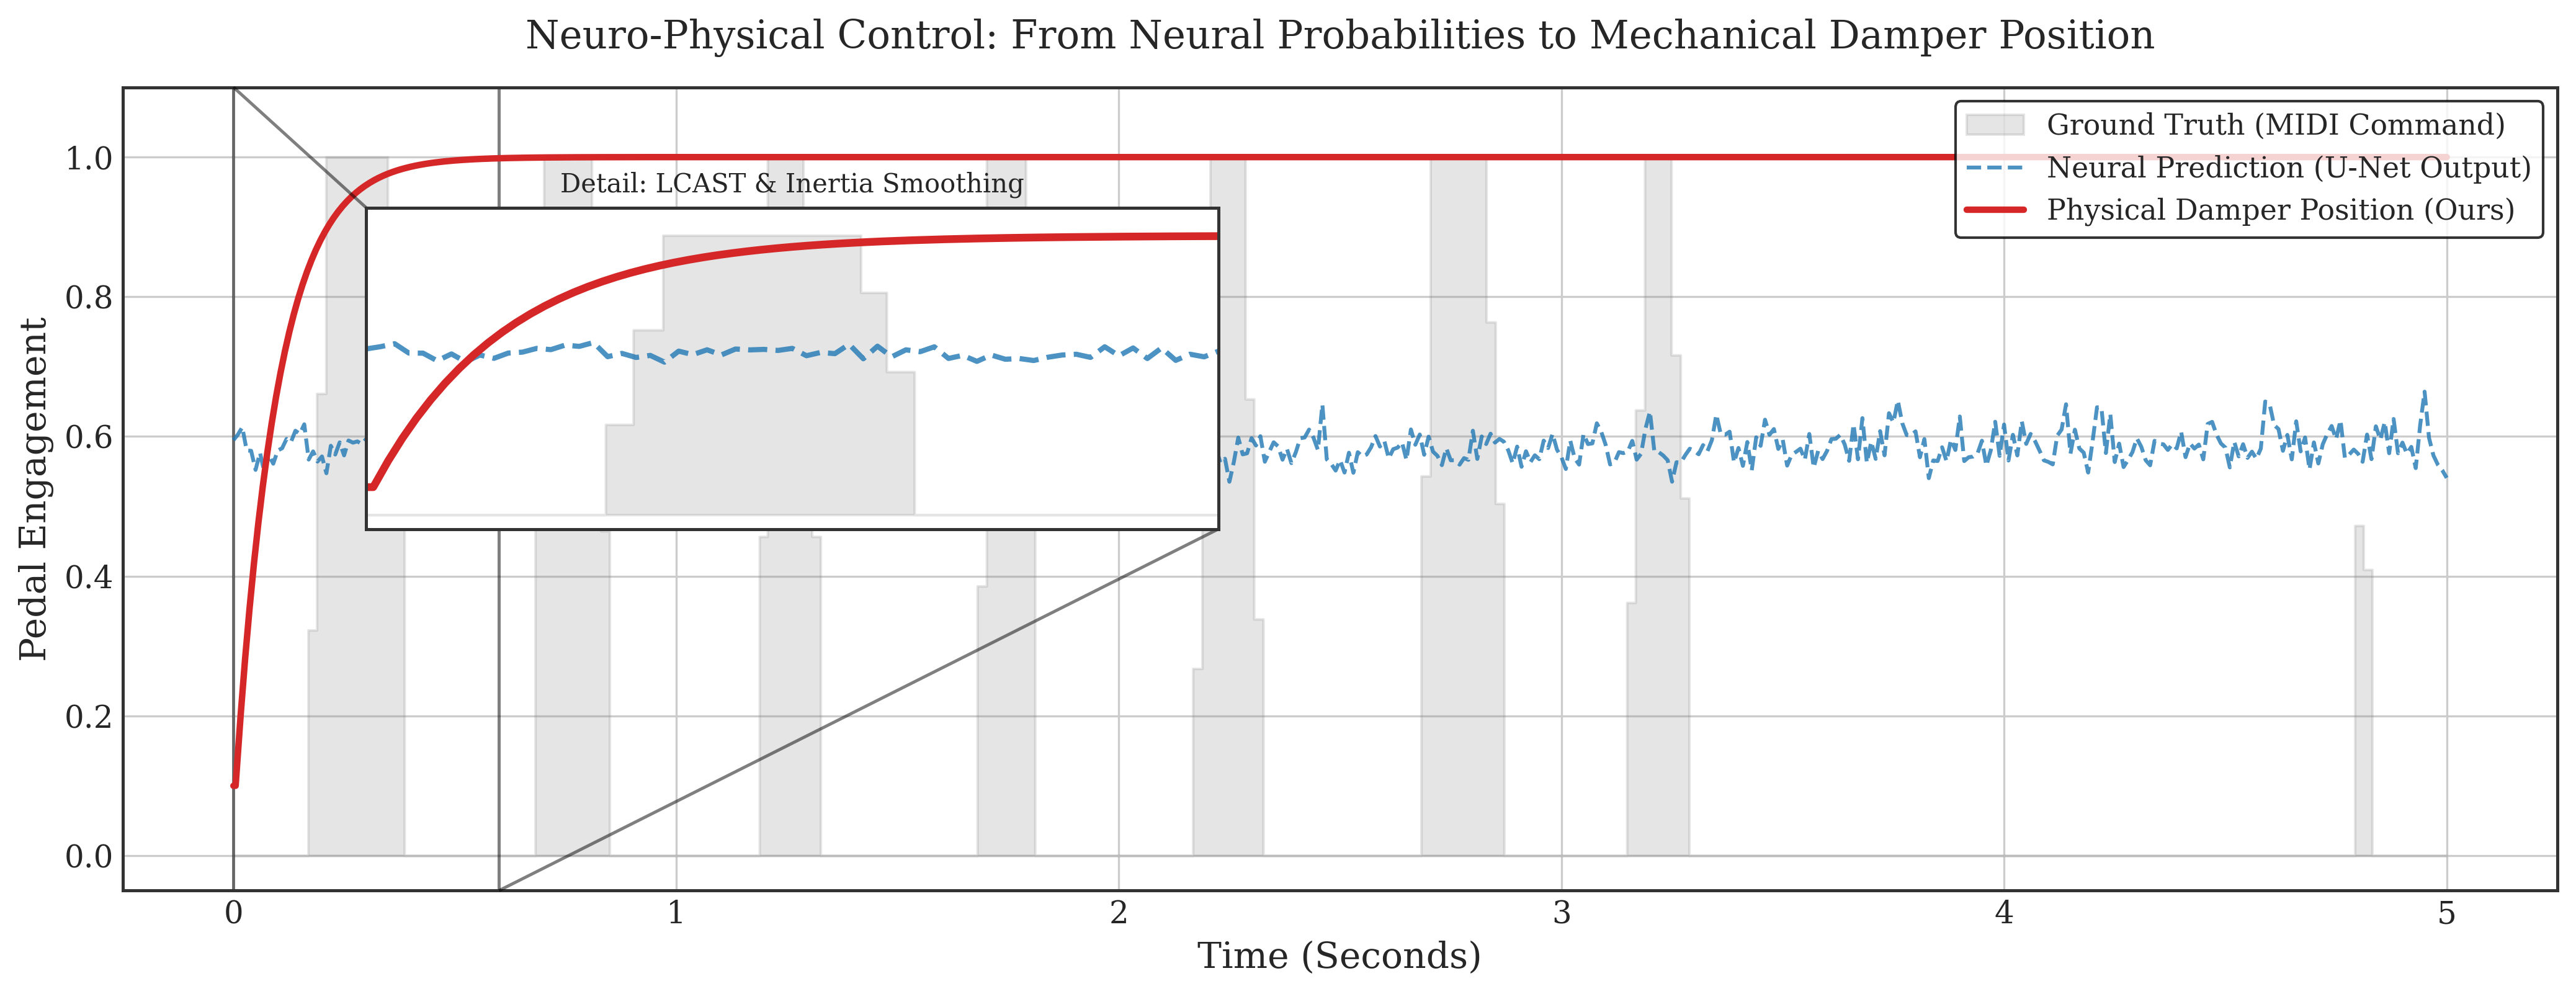

In [4]:
# --- Cell 4: Figure 1 - Control Logic & Mechanical Inertia (With Zoom-in Inset) ---
fig, ax = plt.subplots(figsize=(14, 5.5))

# Interpolate the Ground Truth to match the audio timeline for perfect square wave fill
gt_interpolated = np.interp(time_axis_audio, np.linspace(0, 5.0, len(pedal_gt)), pedal_gt)

# 1. Plot Ground Truth (as background shadow, print-friendly in black and white)
ax.fill_between(time_axis_audio, 0, gt_interpolated, color='gray', alpha=0.2, step='post', 
                label='Ground Truth (MIDI Command)')

# 2. Plot Neural Prediction (dashed line, showing raw network jitter)
ax.plot(time_axis_frames, probs_np, color='#1f77b4', linestyle='--', linewidth=1.5, alpha=0.8, 
        label='Neural Prediction (U-Net Output)')

# 3. Plot Physical Position (thick solid line, showing the smoothness of physical inertia)
ax.plot(time_axis_audio, pos_np, color='#d62728', linewidth=2.5, 
        label='Physical Damper Position (Ours)')

ax.set_title("Neuro-Physical Control: From Neural Probabilities to Mechanical Damper Position", pad=15)
ax.set_xlabel("Time (Seconds)")
ax.set_ylabel("Pedal Engagement")
ax.set_ylim(-0.05, 1.1)
ax.legend(loc='upper right', frameon=True, edgecolor='black')

# Adding Local Zoom-in Inset
# Automatically find the first pedal press interval as the zoom area
first_press_idx = np.argmax(probs_np > 0.5)
zoom_center_time = time_axis_frames[first_press_idx]
zoom_start = max(0, zoom_center_time - 0.2)
zoom_end = min(5.0, zoom_center_time + 0.6)

# Create a picture-in-picture coordinate system (x, y, width, height relative proportions)
axins = ax.inset_axes([0.1, 0.45, 0.35, 0.4])
axins.fill_between(time_axis_audio, 0, gt_interpolated, color='gray', alpha=0.2, step='post')
axins.plot(time_axis_frames, probs_np, color='#1f77b4', linestyle='--', linewidth=2, alpha=0.8)
axins.plot(time_axis_audio, pos_np, color='#d62728', linewidth=3)

# Set the coordinate axis range of the zoomed-in area
axins.set_xlim(zoom_start, zoom_end)
axins.set_ylim(-0.05, 1.1)
axins.set_xticklabels([])
axins.set_yticklabels([])
axins.grid(False)
axins.set_title("Detail: LCAST & Inertia Smoothing", fontsize=10)

# Draw connecting lines
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="black", lw=1.2, alpha=0.5)

plt.tight_layout()
plt.savefig("fig_control_inertia_academic.pdf", bbox_inches='tight')
plt.show()

C:\Users\lenovo\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


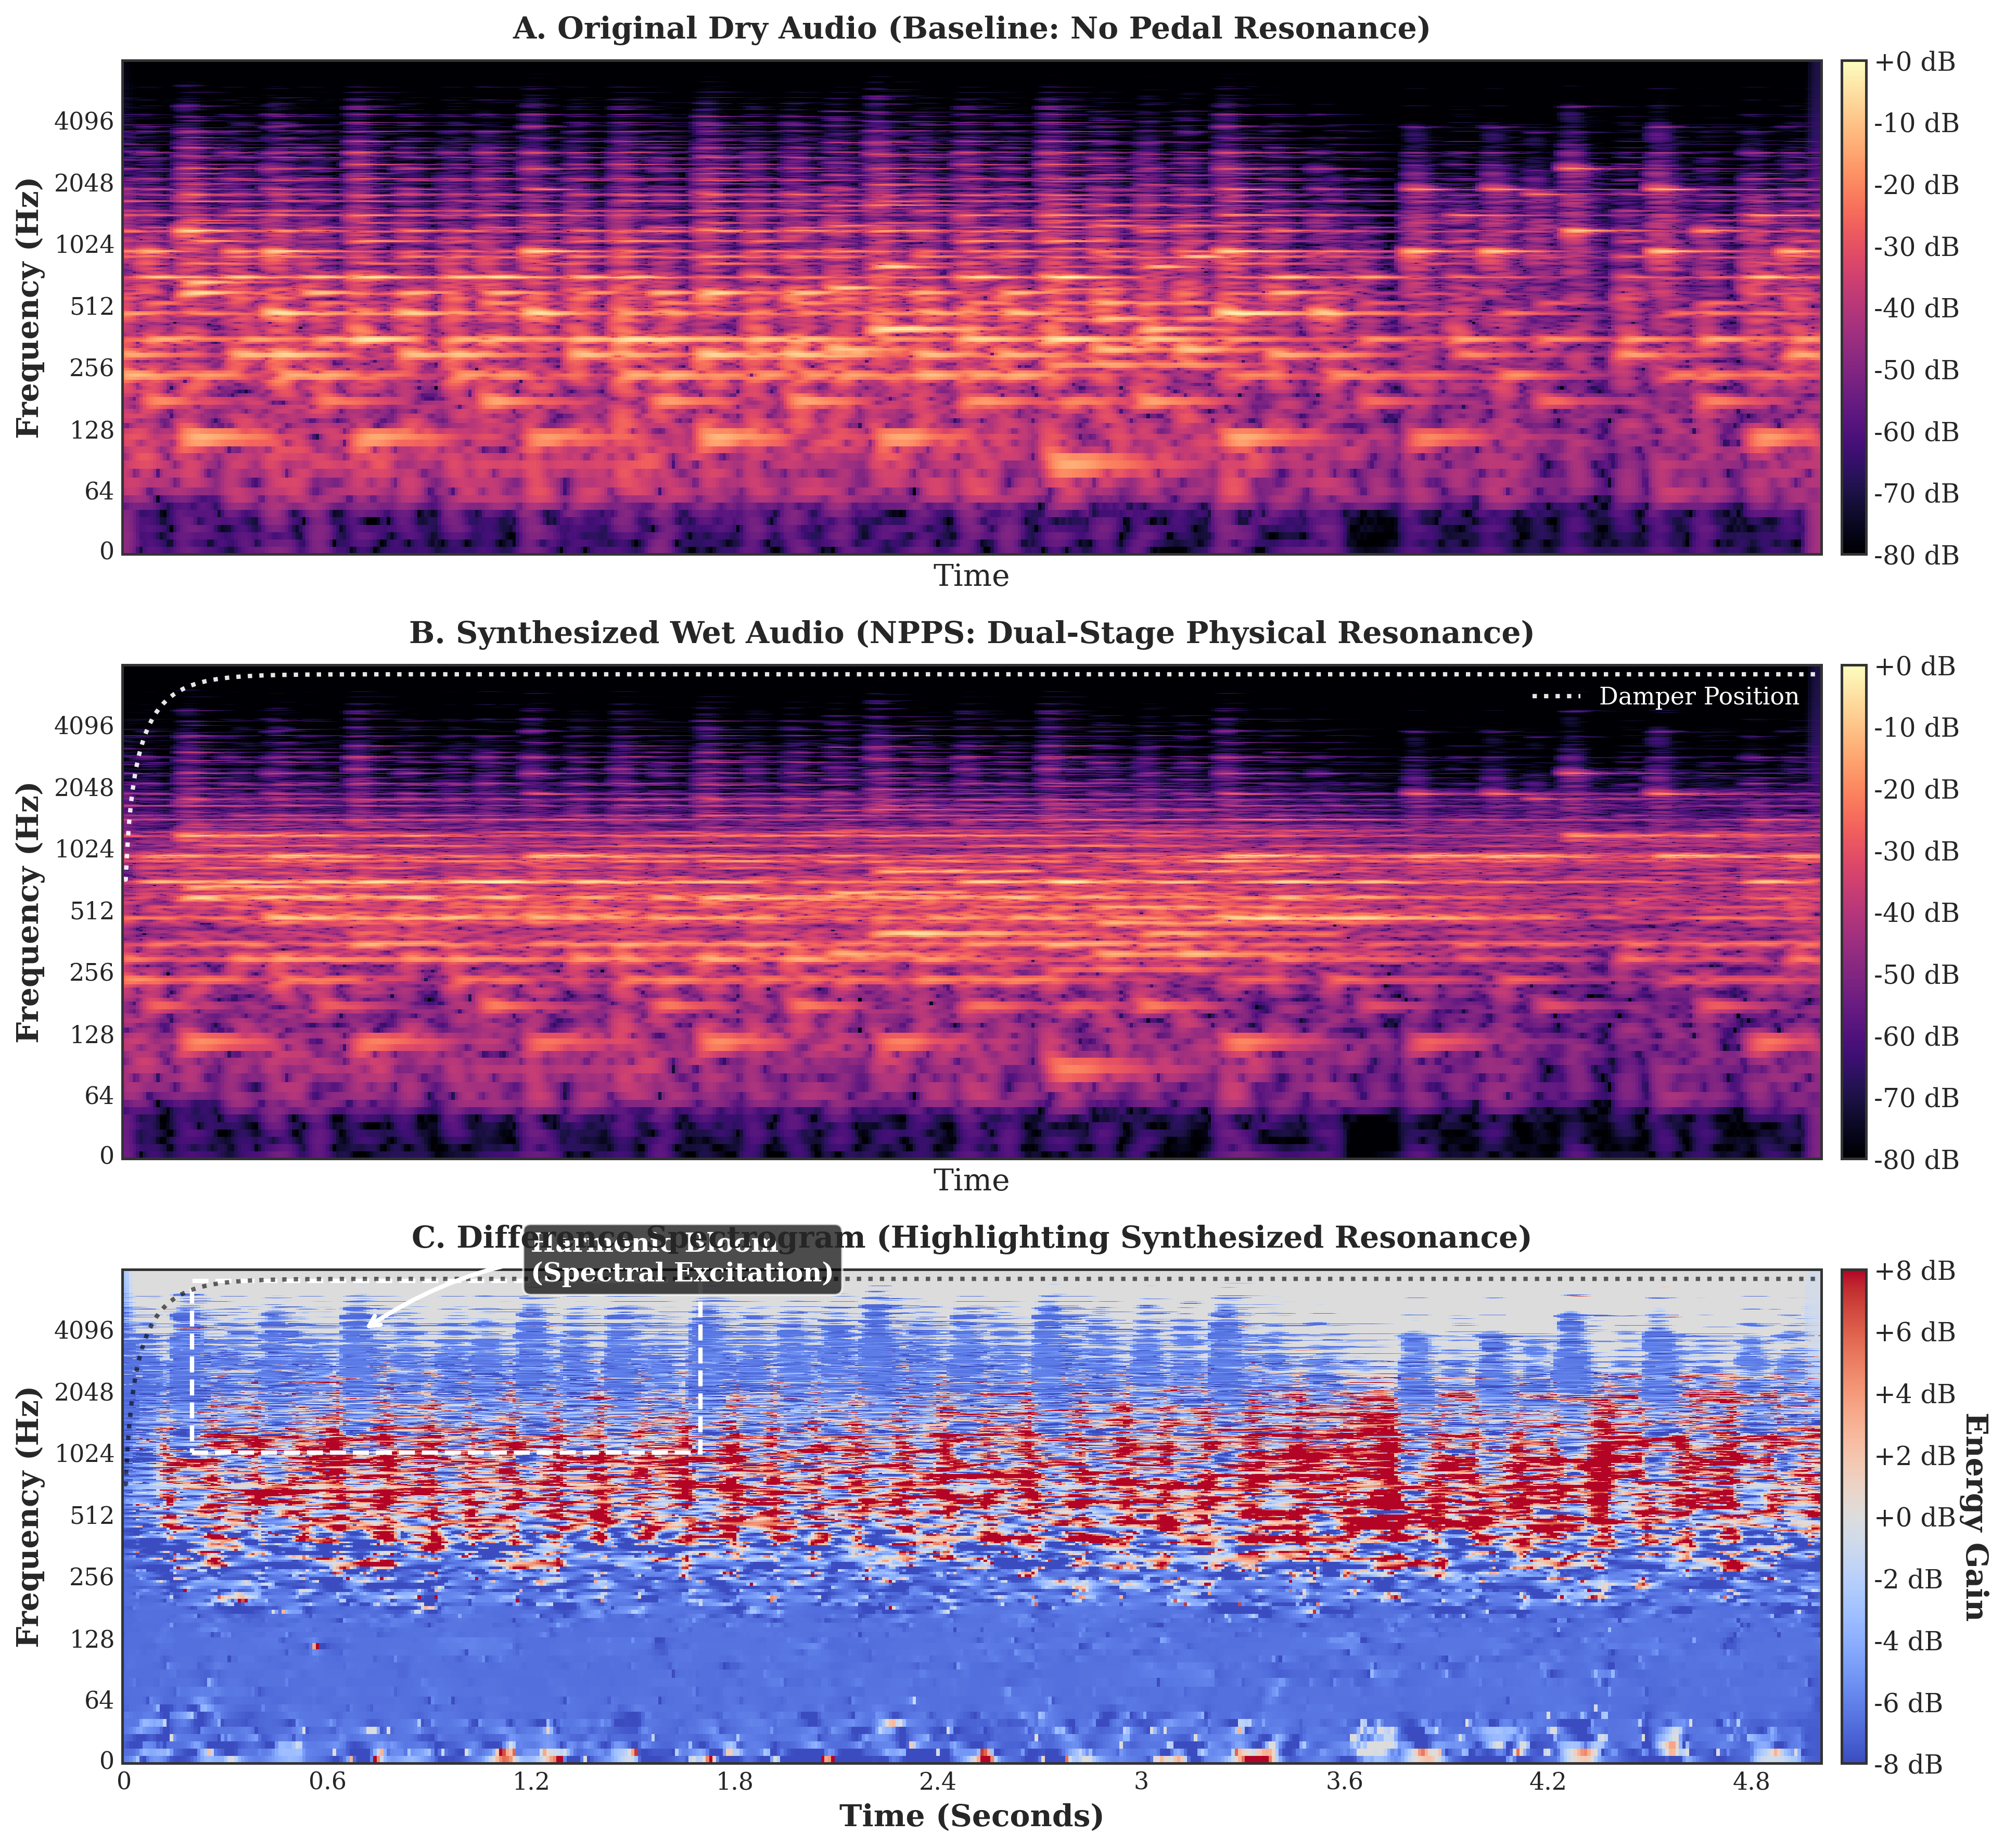

In [5]:
# --- Cell 5: Figure 2 - Spectral Bloom and Acoustic Synthesis (With Bounding Boxes) ---
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

n_fft = 2048
hop_length = 160
sr = 16000

# Calculate Spectrograms
D_dry = librosa.amplitude_to_db(np.abs(librosa.stft(audio_dry_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
D_wet = librosa.amplitude_to_db(np.abs(librosa.stft(audio_wet_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
min_len = min(D_dry.shape[1], D_wet.shape[1])
D_diff = D_wet[:, :min_len] - D_dry[:, :min_len]

# Plot A: Dry Audio
ax1 = axes[0]
img1 = librosa.display.specshow(D_dry, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax1, cmap='magma')
ax1.set_title("A. Original Dry Audio (Baseline: No Pedal Resonance)", fontsize=14, fontweight='bold', pad=10)
fig.colorbar(img1, ax=ax1, format="%+2.0f dB", pad=0.01)

# Plot B: Wet Audio (Ours)
ax2 = axes[1]
img2 = librosa.display.specshow(D_wet, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax2, cmap='magma')
ax2.plot(time_axis_audio, pos_np * (sr/2)*0.9, color='white', linewidth=2, linestyle=':', alpha=0.9, label='Damper Position')
ax2.set_title("B. Synthesized Wet Audio (NPPS: Dual-Stage Physical Resonance)", fontsize=14, fontweight='bold', pad=10)
ax2.legend(loc='upper right', facecolor='black', edgecolor='white', labelcolor='white')
fig.colorbar(img2, ax=ax2, format="%+2.0f dB", pad=0.01)

# Plot C: Difference (The "Bloom" Effect)
ax3 = axes[2]
vmax = 8 # High-sensitivity threshold
img3 = librosa.display.specshow(D_diff, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax3, cmap='coolwarm', vmin=-vmax, vmax=vmax)
ax3.plot(time_axis_audio, pos_np * (sr/2)*0.9, color='black', linewidth=2, linestyle=':', alpha=0.6)
ax3.set_title("C. Difference Spectrogram (Highlighting Synthesized Resonance)", fontsize=14, fontweight='bold', pad=10)
cbar = fig.colorbar(img3, ax=ax3, format="%+2.0f dB", pad=0.01)
cbar.set_label("Energy Gain", rotation=270, labelpad=15, fontweight='bold')

# Bounding Boxes and Annotations
# Draw a box at the point where the first pedal is pressed to mark the high-frequency overtone range
highlight_start = zoom_center_time + 0.2
highlight_end = highlight_start + 1.5
rect = patches.Rectangle((highlight_start, 1024), highlight_end - highlight_start, 6000, 
                         linewidth=2, edgecolor='white', facecolor='none', linestyle='dashed')
ax3.add_patch(rect)

# Add text descriptions with arrows
ax3.annotate('Harmonic Bloom\n(Spectral Excitation)', 
             xy=(highlight_start + 0.5, 4000), xycoords='data',
             xytext=(highlight_start + 1.0, 7000), textcoords='data',
             color='white', fontweight='bold', fontsize=12,
             bbox=dict(boxstyle="round,pad=0.3", fc="black", ec="white", alpha=0.7),
             arrowprops=dict(arrowstyle="->", color="white", lw=2, connectionstyle="arc3,rad=0.2"))

# Clean up axes formatting
for ax in axes:
    ax.set_ylabel("Frequency (Hz)", fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=11)

axes[2].set_xlabel("Time (Seconds)", fontweight='bold', fontsize=14)
plt.tight_layout()

plt.savefig("fig_spectral_bloom_academic.pdf", bbox_inches='tight')
plt.show()